# 1. Project Introduction
This notebook acquires, cleans, and explores the real Mauna Loa weekly atmospheric CO₂ dataset distributed by Statsmodels. It also regenerates the project CSVs, figures, summary, and DOCX through the shared analysis pipeline. CO₂ is measured in parts per million (ppm).

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src' / 'analysis.py').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from analysis import DATASET_URL, run_analysis

## 2. Dataset Description
Statsmodels provides a weekly atmospheric CO₂ series measured at Mauna Loa. The source interface is `statsmodels.datasets.co2`; its documentation is [here](https://www.statsmodels.org/devel/datasets/generated/co2.html). The observed dates and missingness are derived from the loaded data below.

In [2]:
print('Source:', DATASET_URL)
print('Measurement unit: parts per million (ppm)')

Source: https://www.statsmodels.org/devel/datasets/generated/co2.html
Measurement unit: parts per million (ppm)


## 3. Data Acquisition
Load the public dataset with the Statsmodels API and save both original and cleaned data, plus the supporting project outputs. The original CSV retains missing readings.

In [3]:
results = run_analysis(PROJECT_ROOT)
raw = results['raw']
clean = results['clean']
details = results['details']
statistics = results['statistics']
figures = results['figures']
print('Raw CSV:', PROJECT_ROOT / 'data' / 'co2_raw_acquired.csv')
print('Cleaned CSV:', PROJECT_ROOT / 'data' / 'co2_cleaned.csv')

Raw CSV: /workspaces/week1-co2-data-analysis/data/co2_raw_acquired.csv
Cleaned CSV: /workspaces/week1-co2-data-analysis/data/co2_cleaned.csv


## 4. Initial Data Inspection
Inspect dimensions, column names, source types, dates, missing readings, duplicate dates, and raw descriptive statistics before cleaning.

In [4]:
print('Shape:', raw.shape)
print('Columns:', raw.columns.tolist())
print('Index type:', type(raw.index).__name__)
print('Value dtypes:\n', raw.dtypes)
print('Date range:', raw.index.min(), 'to', raw.index.max())
print('Missing values:\n', raw.isna().sum())
print('Duplicate dates:', int(raw.index.duplicated().sum()))
raw['co2'].describe(percentiles=[0.25, 0.5, 0.75])

Shape: (2284, 1)
Columns: ['co2']
Index type: DatetimeIndex
Value dtypes:
 co2    float64
dtype: object
Date range: 1958-03-29 00:00:00 to 2001-12-29 00:00:00
Missing values:
 co2    59
dtype: int64
Duplicate dates: 0


count    2225.000000
mean      340.142247
std        17.003885
min       313.000000
25%       324.800000
50%       338.300000
75%       354.800000
max       373.900000
Name: co2, dtype: float64

## 5. Missing Value Analysis
Missing values are measured before cleaning. Since these are regularly sampled time-series data, the pipeline uses time-based interpolation for interior gaps. It does not silently extrapolate unresolved edge gaps. A global mean would ignore when a value is missing and flatten local temporal variation.

In [5]:
missing_count = int(raw['co2'].isna().sum())
missing_by_year = raw['co2'].isna().resample('YS').sum()
print(f'Missing CO₂ observations before cleaning: {missing_count}')
print('Missing values by year with gaps:')
missing_by_year[missing_by_year > 0]

Missing CO₂ observations before cleaning: 59
Missing values by year with gaps:


date
1958-01-01    15
1959-01-01     4
1962-01-01     4
1963-01-01     3
1964-01-01    21
1966-01-01     4
1967-01-01     2
1976-01-01     1
1984-01-01     4
1985-01-01     1
Name: co2, dtype: int64

## 6. Data Cleaning
The shared cleaning function parses and validates a DatetimeIndex, converts CO₂ values with `pd.to_numeric(..., errors='coerce')`, sorts observations chronologically, removes duplicate dates only, and interpolates interior missing values with `method='time'`. Repeated CO₂ values on distinct dates are valid observations and are retained.

In [6]:
# Reproduce the key cleaning operations for direct inspection.
cleaning_check = raw.copy()
cleaning_check.index = pd.DatetimeIndex(pd.to_datetime(cleaning_check.index, errors='coerce'), name='date')
cleaning_check['co2'] = pd.to_numeric(cleaning_check['co2'], errors='coerce')
cleaning_check = cleaning_check.sort_index(kind='stable')
cleaning_check = cleaning_check.loc[~cleaning_check.index.duplicated(keep='first')].copy()
cleaning_check['co2'] = cleaning_check['co2'].interpolate(method='time', limit_area='inside')
assert cleaning_check.equals(clean)
print('Cleaning check matches pipeline output:', cleaning_check.equals(clean))
print('Filled values:', missing_count - int(clean['co2'].isna().sum()))

Cleaning check matches pipeline output: True
Filled values: 59


## 7. Duplicate Validation
Duplicate observations are records sharing the same date. Equal values on different dates are not duplicates. The current source has no duplicate dates; the pipeline's explicit keep-first policy applies only if repeated dates appear in a future source version.

In [7]:
print('Duplicate dates before cleaning:', int(raw.index.duplicated().sum()))
print('Duplicate dates after cleaning:', int(clean.index.duplicated().sum()))
print('Duplicate date records removed:', details['duplicate_dates_removed'])

Duplicate dates before cleaning: 0
Duplicate dates after cleaning: 0
Duplicate date records removed: 0


## 8. Data Type Validation
The time index must be a DatetimeIndex and the CO₂ column numeric. Numeric coercion turns invalid entries into missing values so they cannot silently contaminate statistics.

In [8]:
print('Clean index type:', type(clean.index).__name__)
print('Clean value dtype:', clean['co2'].dtype)
assert isinstance(clean.index, pd.DatetimeIndex)
assert pd.api.types.is_numeric_dtype(clean['co2'])
print('Rows:', len(clean))
print('Range:', clean.index.min(), 'to', clean.index.max())
print('Missing after cleaning:', int(clean.isna().sum().sum()))

Clean index type: DatetimeIndex
Clean value dtype: float64
Rows: 2284
Range: 1958-03-29 00:00:00 to 2001-12-29 00:00:00
Missing after cleaning: 0


## 9. Descriptive Statistics
The following summary statistics describe the cleaned observations. The count includes interpolated values, so estimates should be interpreted with that qualification.

In [9]:
clean['co2'].describe(percentiles=[0.25, 0.5, 0.75]).rename({'50%': 'median'})

count     2284.000000
mean       339.652496
std         17.103561
min        313.000000
25%        323.975000
median     337.700000
75%        354.500000
max        373.900000
Name: co2, dtype: float64

## 10. Exploratory Data Analysis
Annual means reduce within-year fluctuations. Calendar-month means summarize the average seasonal profile across all years. A simple least-squares trend is fitted against elapsed years; it describes association with time and does not prove causation.

In [10]:
annual_mean = statistics['annual_series']
monthly_mean = statistics['monthly_series']
print(f"Linear trend: {statistics['trend_ppm_per_year']:.3f} ppm/year")
print(f"Trend R-squared: {statistics['trend_r_squared']:.3f}")
print(f"Annual mean: {statistics['annual_first_mean']:.3f} ppm ({statistics['annual_first_year']}) to {statistics['annual_last_mean']:.3f} ppm ({statistics['annual_last_year']})")
print(f"Monthly mean range: {statistics['monthly_range']:.3f} ppm")
display(annual_mean.rename('annual_mean_ppm').to_frame().head())
display(monthly_mean.rename('monthly_mean_ppm').to_frame())

Linear trend: 1.335 ppm/year
Trend R-squared: 0.974
Annual mean: 315.188 ppm (1958) to 370.865 ppm (2001)
Monthly mean range: 5.480 ppm


,annual_mean_ppm
date,
1958-01-01,315.187500
1959-01-01,315.957692
1960-01-01,316.860377
1961-01-01,317.592308
1962-01-01,318.451923


,monthly_mean_ppm
date,
1,339.494847
2,340.223367
3,341.091299
4,341.723965
5,342.193036
6,341.821011
7,340.324103
8,338.274615
9,336.896120


## 11. Visualizations
Five figures are generated by the analysis pipeline and inserted here from the actual output files.

01_missing_values.png


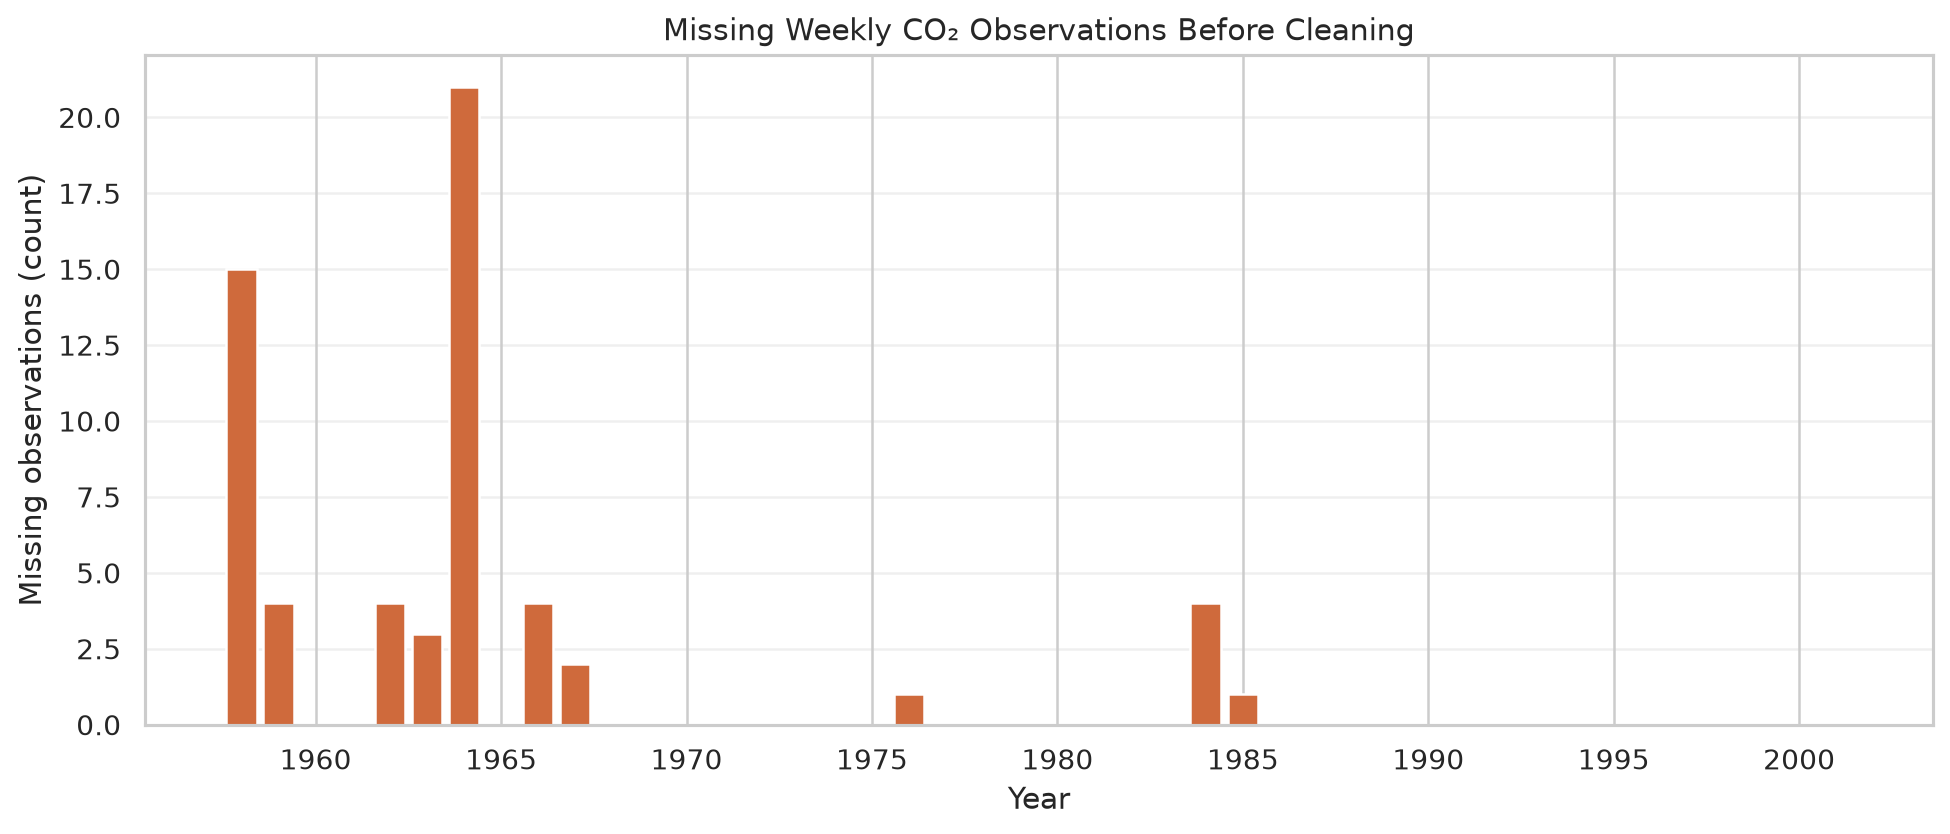

02_co2_time_series.png


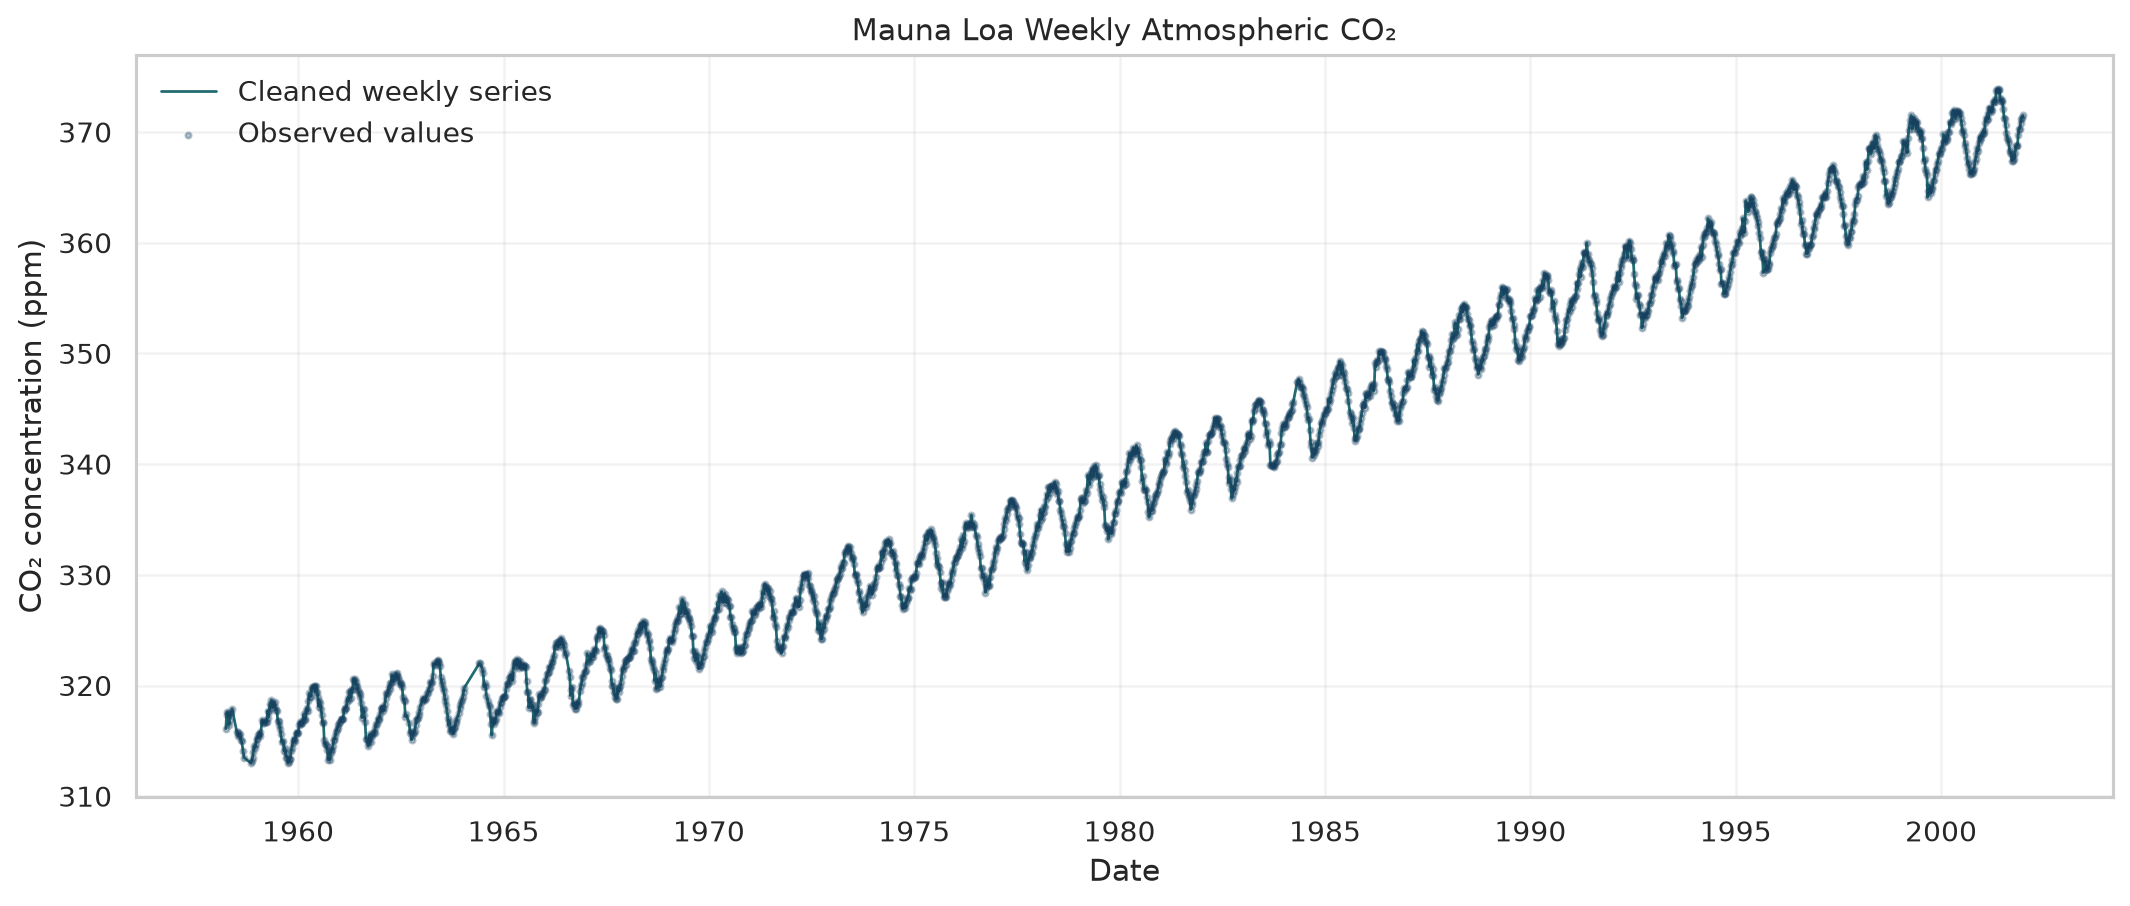

03_annual_mean.png


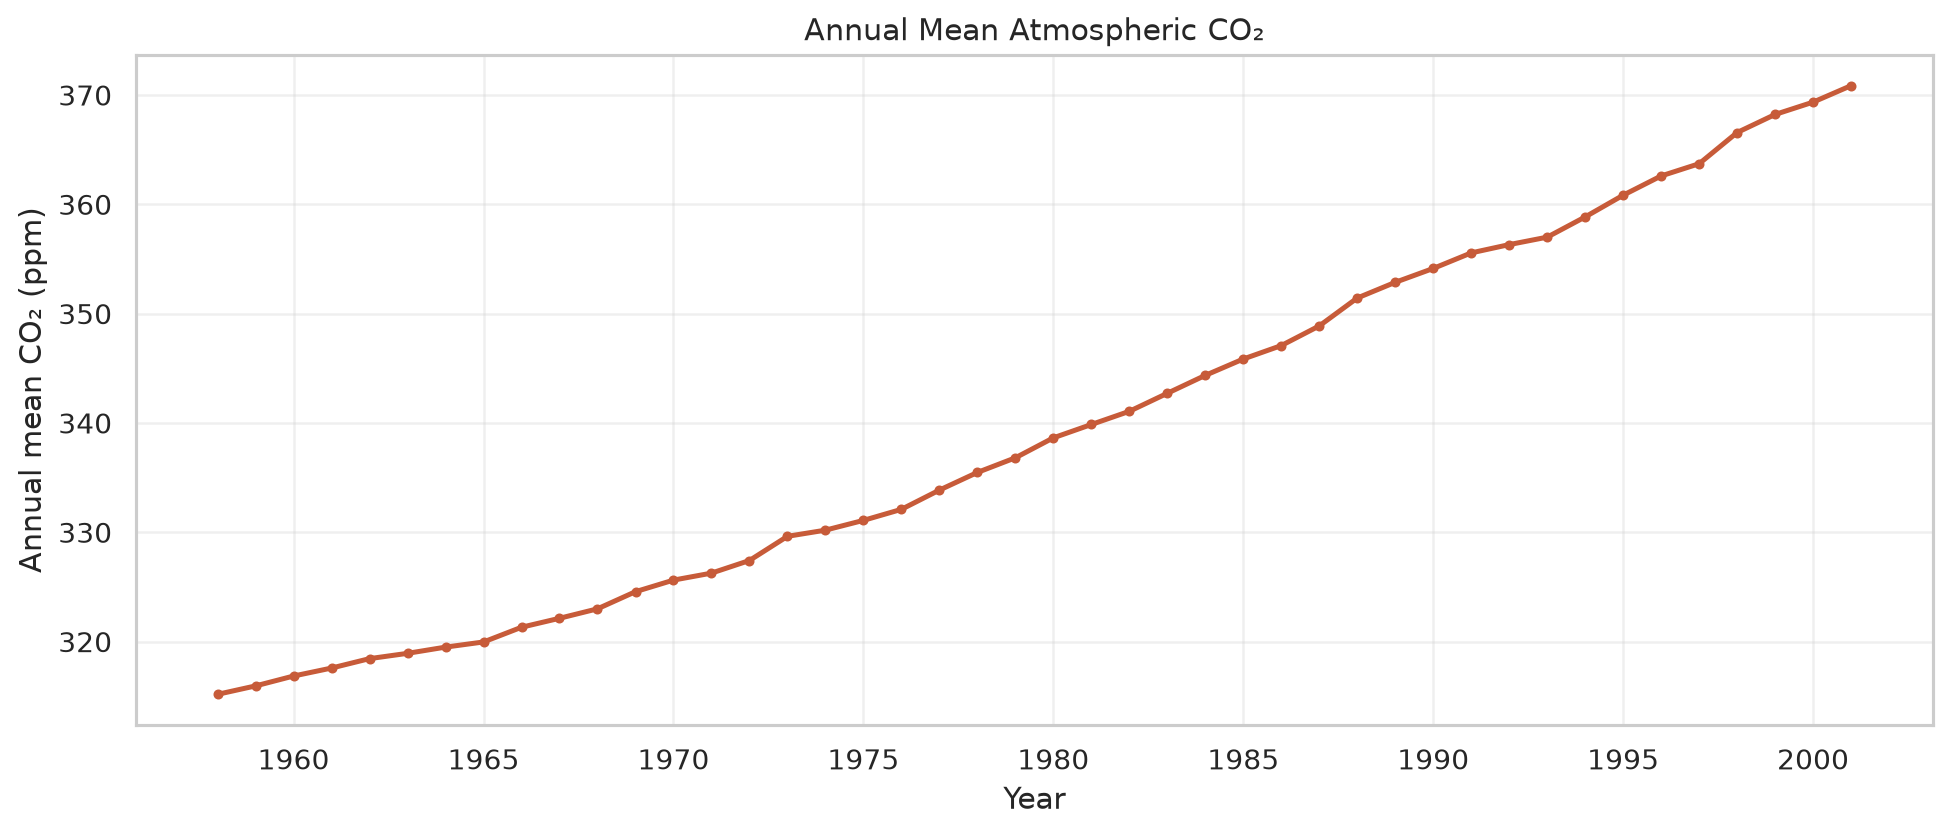

04_distribution.png


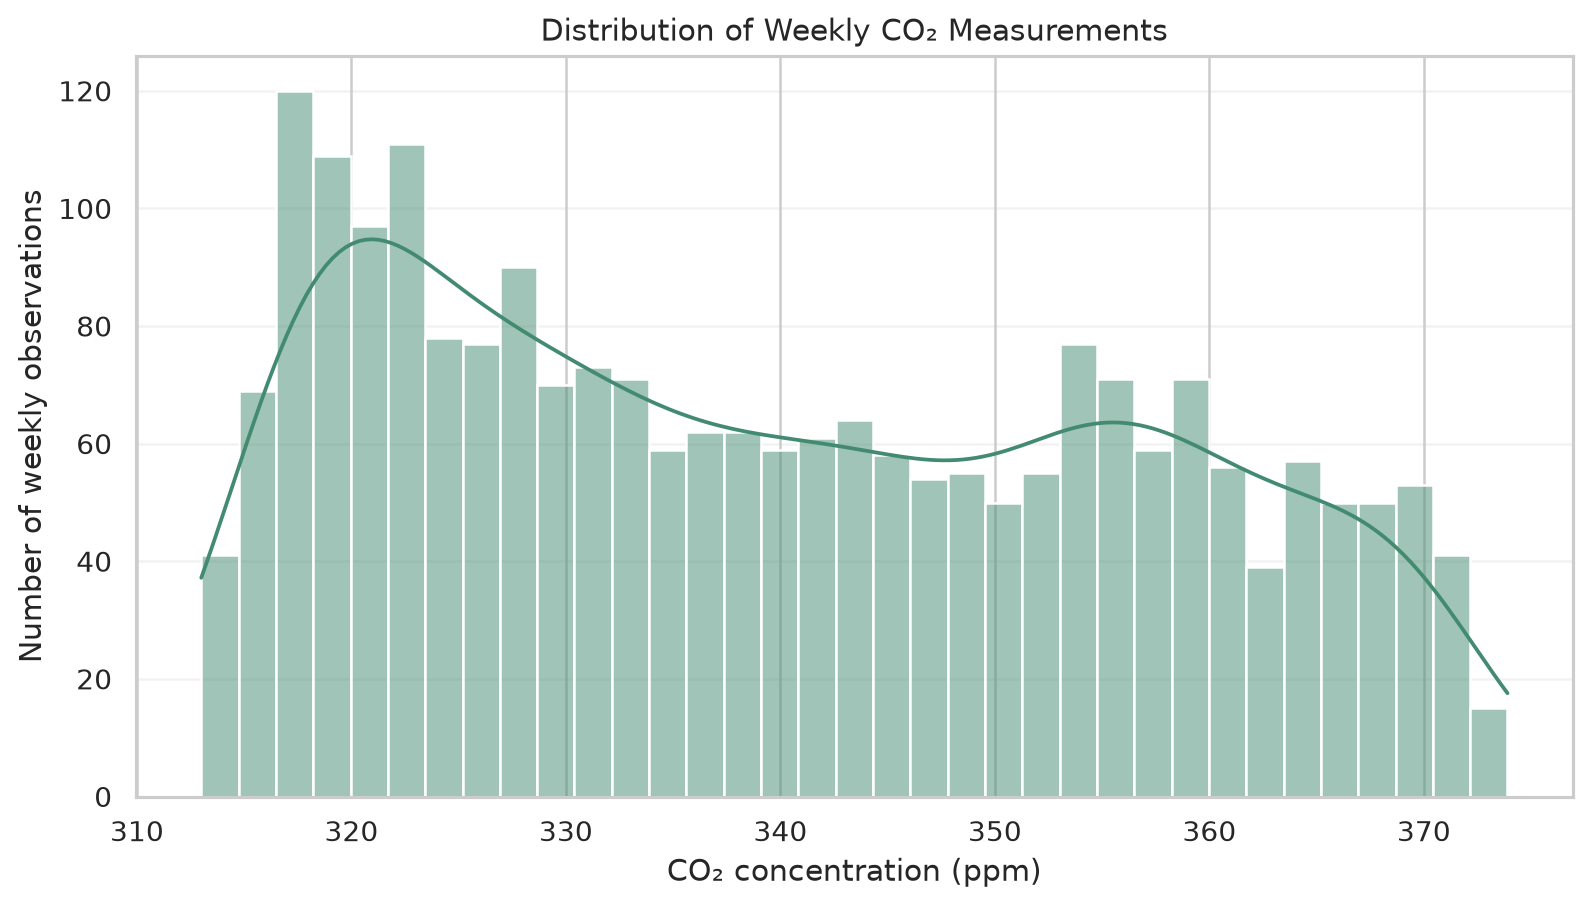

05_monthly_pattern.png


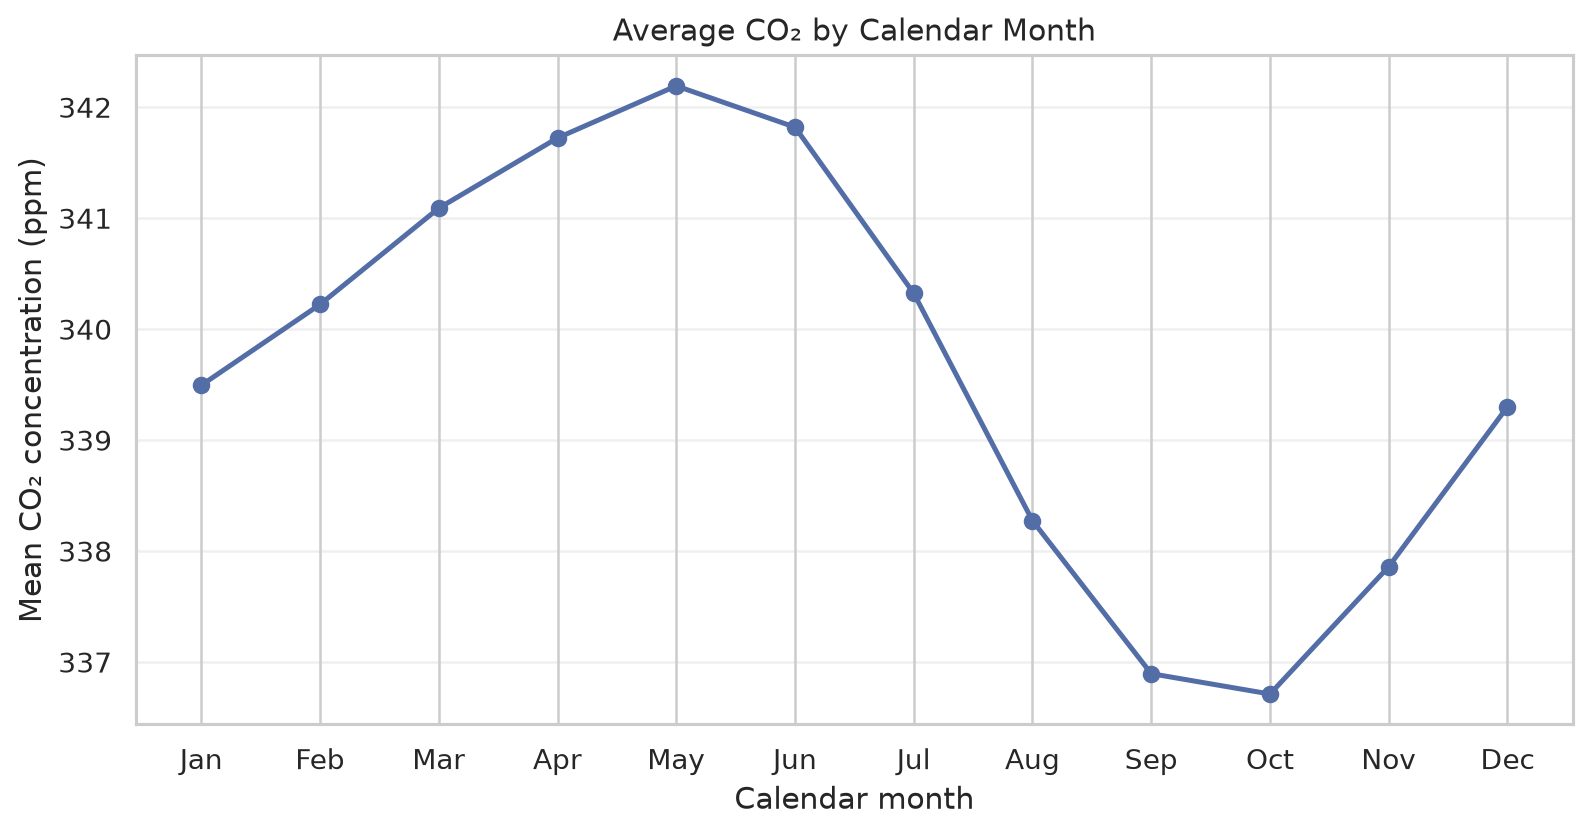

In [11]:
for key in ('missing', 'time_series', 'annual', 'distribution', 'monthly'):
    print(figures[key].name)
    display(Image(filename=str(figures[key])))

## 12. Key Findings
Findings below are calculated directly from this dataset. The linear fit and summary patterns are descriptive, not causal.

In [12]:
desc = statistics['descriptive']
print(f"{details['raw_rows']} raw observations; {details['raw_missing']} missing measurements; {details['duplicate_dates_removed']} duplicate dates.")
print(f"The cleaned series has {details['clean_rows']} rows and {details['clean_missing']} missing values.")
print(f"Date range: {details['clean_start']:%Y-%m-%d} to {details['clean_end']:%Y-%m-%d}.")
print(f"Mean {desc['mean']:.2f} ppm; median {desc['50%']:.2f} ppm; standard deviation {desc['std']:.2f} ppm.")
print(f"Linear trend {statistics['trend_ppm_per_year']:.3f} ppm/year (R² {statistics['trend_r_squared']:.3f}).")
print(f"Annual means differ by {statistics['annual_mean_change']:.2f} ppm from {statistics['annual_first_year']} to {statistics['annual_last_year']}.")
print(f"Monthly mean minimum: month {statistics['monthly_min_month']}; maximum: month {statistics['monthly_max_month']}; range {statistics['monthly_range']:.2f} ppm.")

2284 raw observations; 59 missing measurements; 0 duplicate dates.
The cleaned series has 2284 rows and 0 missing values.
Date range: 1958-03-29 to 2001-12-29.
Mean 339.65 ppm; median 337.70 ppm; standard deviation 17.10 ppm.
Linear trend 1.335 ppm/year (R² 0.974).
Annual means differ by 55.68 ppm from 1958 to 2001.
Monthly mean minimum: month 10; maximum: month 5; range 5.48 ppm.


## 13. Limitations
The series represents one monitoring location. Interpolation estimates missing values and may smooth short-lived changes. Aggregation hides weekly detail, and pooling many decades combines seasonal variation with the long-term trend. The fitted straight line does not model seasonal components explicitly and cannot establish causality.

## 14. Conclusion
The Statsmodels data were acquired, inspected, cleaned, and analyzed through a shared reproducible pipeline. The measured record has a clear long-term increasing pattern alongside recurring within-year variation. All conclusions are descriptive and apply to this dataset and time period.